# Sharpe ratio explorer: S&P 500

Enter a ticker and this notebook calculates its Sharpe ratio over the last 1, 2, 3 and 5 years from `sp500_panel.csv`,
compares it with its sector and the whole index, and writes a Markdown report with charts. See `README.md` for setup.

It also calculates the same table for **every** ticker, and writes the BigQuery SQL that produces that table in BigQuery,
so the two can be checked against each other.

**Method**
- Daily return = today's `adj_close` / previous trading day's `adj_close` - 1 (total return: dividends included).
- Daily excess return = daily return - the daily risk-free rate, where daily rate = (1 + annual rate)^(1/252) - 1.
- Daily Sharpe = mean daily excess return / standard deviation of daily returns (sample standard deviation).
- Annualised Sharpe = daily Sharpe x sqrt(252). This is the number reported as `sharpe_ratio`.
- A window of N years runs from the close N years before the last date in the file to the last close.
  A stock listed for less than N years in the file gets no value for that window rather than a misleading one.

Run the cells top to bottom (or Run All). You will be asked for a ticker in step 2.

In [1]:
# Run once, then you can comment it out again
# %pip install pandas numpy matplotlib

## 0. Settings

In [2]:
CSV_PATH = "sp500_panel.csv"           # same folder as this notebook, or a full path
TICKER = None                          # None = ask for one; or set it, e.g. "NVDA", to skip the prompt
HORIZONS_YEARS = [1, 2, 3, 5]
RISK_FREE_RATE = 0.04                  # annual, e.g. the average 3-month T-bill yield over the period
TRADING_DAYS = 252
OUT_DIR = "sharpe_output"              # report, charts and the all-ticker table are written here
EMBED_IMAGES_IN_MARKDOWN = True        # True: one self-contained .md file; False: .md that links to the .png files
BQ_TABLE = None                        # e.g. "your_project.your_dataset.sp500_panel" to also run the BigQuery version

## 1. Load the data
Errors you can fix (a missing file, a wrong ticker) are shown as a one-line message in red, not a Python traceback.

In [3]:
import re
import sys
import base64
import difflib
from io import BytesIO
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


class SharpeError(Exception):
    """A problem the user can fix. Shown as a plain message, not a traceback."""


def _show_error(shell, etype, evalue, tb, tb_offset=None):
    print(f"Error: {evalue}", file=sys.stderr)


try:
    get_ipython().set_custom_exc((SharpeError,), _show_error)
except NameError:                                  # not running inside Jupyter
    pass


REQUIRED_COLUMNS = ["date", "ticker", "company", "sector", "adj_close"]


def load_panel(path: str) -> pd.DataFrame:
    """Read the columns this notebook needs from sp500_panel.csv and check they are in the expected format."""
    p = Path(path)
    if not p.exists():
        raise SharpeError(f"Cannot find '{p.resolve()}'. Put sp500_panel.csv next to this notebook, "
                          "or set CSV_PATH in the settings cell to its full path.")
    try:
        header = pd.read_csv(p, nrows=0).columns
    except Exception as e:
        raise SharpeError(f"Cannot read '{p.name}' as a CSV file ({e}).") from None
    missing = [c for c in REQUIRED_COLUMNS if c not in header]
    if missing:
        raise SharpeError(f"'{p.name}' has no column(s) {', '.join(missing)}. "
                          f"Expected the sp500_panel.csv format; see README.md.")

    df = pd.read_csv(p, usecols=REQUIRED_COLUMNS, dtype={"ticker": str, "company": str, "sector": str})
    df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")
    df["adj_close"] = pd.to_numeric(df["adj_close"], errors="coerce")
    if df["date"].isna().any():
        raise SharpeError(f"{df['date'].isna().sum():,} rows have a date that is not in YYYY-MM-DD format.")
    dupes = df.duplicated(["ticker", "date"]).sum()
    if dupes:
        raise SharpeError(f"{dupes:,} rows repeat a ticker and date. Each ticker should have one row per trading day.")
    df = df.dropna(subset=["adj_close"]).sort_values(["ticker", "date"]).reset_index(drop=True)
    if df.empty:
        raise SharpeError(f"'{p.name}' has no rows with an adj_close price.")
    df["daily_return"] = df.groupby("ticker")["adj_close"].pct_change()
    return df


panel = load_panel(CSV_PATH)
companies = panel.drop_duplicates("ticker", keep="last").set_index("ticker")[["company", "sector"]]
END_DATE = panel["date"].max()
print(f"{len(panel):,} rows, {len(companies)} tickers, {panel['date'].min():%Y-%m-%d} to {END_DATE:%Y-%m-%d}")

622,710 rows, 503 tickers, 2021-10-08 to 2026-10-08


## 2. Choose a ticker
Type a symbol such as `AAPL` or `BRK.B` (`BRK-B` and lower case work too). A wrong entry gets an error message and,
where possible, suggestions; you get three tries. Pressing Enter on an empty box cancels.

In [4]:
def resolve_ticker(text: str) -> str:
    raw = (text or "").strip()
    t = raw.upper().lstrip("$").replace("-", ".").replace("/", ".")
    if not t:
        raise SharpeError("No ticker entered. Type an S&P 500 symbol such as AAPL or BRK.B.")
    if t in companies.index:
        return t
    # not a symbol: try it as part of a company name ("apple"), then as a near-miss symbol ("APPL")
    names = companies["company"].str.upper()
    by_name = names[names.str.contains(re.escape(raw.upper()), na=False)].index.tolist() if len(raw) >= 3 else []
    by_symbol = difflib.get_close_matches(t, companies.index, n=3, cutoff=0.6)
    suggestions = list(dict.fromkeys(by_name[:3] + by_symbol))
    if not re.fullmatch(r"[A-Z][A-Z.]{0,5}", t) and not suggestions:
        raise SharpeError(f"'{raw}' does not look like a ticker. Use letters only, e.g. MSFT or BRK.B.")
    msg = f"'{raw}' is not an S&P 500 ticker in {Path(CSV_PATH).name}."
    if suggestions:
        msg += " Did you mean " + ", ".join(f"{s} ({companies.at[s, 'company']})" for s in suggestions) + "?"
    raise SharpeError(msg)


if TICKER:
    ticker = resolve_ticker(TICKER)
else:
    for attempt in range(3):
        entry = input("Enter an S&P 500 ticker (e.g. AAPL, BRK.B), or press Enter to cancel: ")
        if not entry.strip():
            raise SharpeError("Cancelled: no ticker entered. Run this cell again to choose one.")
        try:
            ticker = resolve_ticker(entry)
            break
        except SharpeError as e:
            print(f"Error: {e}", file=sys.stderr)
    else:
        raise SharpeError("Three invalid entries. Run this cell again to retry.")

company, sector = companies.loc[ticker, ["company", "sector"]]
first_day = panel.loc[panel["ticker"] == ticker, "date"].min()
print(f"{ticker}: {company} ({sector}), prices from {first_day:%Y-%m-%d} to {END_DATE:%Y-%m-%d}")

Error: Cancelled: no ticker entered. Run this cell again to choose one.


## 3. Sharpe ratios for every ticker
One row per ticker per window. `sharpe_daily` is the unannualised ratio; `sharpe_ratio` = `sharpe_daily` x sqrt(252).
The table is saved as `sharpe_all_tickers.csv`.

In [ ]:
def sharpe_table(panel: pd.DataFrame, horizons, rf: float, n: int = TRADING_DAYS) -> pd.DataFrame:
    rf_daily = (1 + rf) ** (1 / n) - 1
    end = panel["date"].max()
    first = panel.groupby("ticker")["date"].min()
    out = []
    for h in horizons:
        start = end - pd.DateOffset(years=h)
        w = panel[(panel["date"] > start) & (panel["date"] <= end)].dropna(subset=["daily_return"])
        g = w.groupby("ticker")["daily_return"]
        t = pd.DataFrame({
            "trading_days": g.size(),
            "daily_mean_return": g.mean(),
            "daily_volatility": g.std(),                          # sample standard deviation
            "total_return": np.expm1(np.log1p(w["daily_return"]).groupby(w["ticker"]).sum()),
        })
        t["sharpe_daily"] = (t["daily_mean_return"] - rf_daily) / t["daily_volatility"]
        t["sharpe_ratio"] = t["sharpe_daily"] * np.sqrt(n)
        t["annual_return"] = t["daily_mean_return"] * n
        t["annual_volatility"] = t["daily_volatility"] * np.sqrt(n)
        t["full_history"] = first.reindex(t.index) <= start      # listed for the whole window?
        t.loc[~t["full_history"], t.columns.difference(["trading_days", "full_history"])] = np.nan
        out.append(t.assign(horizon_years=h, start_date=start, end_date=end))
    res = pd.concat(out).reset_index().join(companies, on="ticker")
    res["rank_in_index_pct"] = res.groupby("horizon_years")["sharpe_ratio"].rank(pct=True) * 100
    res["rank_in_sector_pct"] = res.groupby(["horizon_years", "sector"])["sharpe_ratio"].rank(pct=True) * 100
    cols = ["ticker", "company", "sector", "horizon_years", "start_date", "end_date", "trading_days", "full_history",
            "daily_mean_return", "daily_volatility", "sharpe_daily", "sharpe_ratio",
            "annual_return", "annual_volatility", "total_return", "rank_in_index_pct", "rank_in_sector_pct"]
    return res[cols]


sharpe_all = sharpe_table(panel, HORIZONS_YEARS, RISK_FREE_RATE)
out_dir = Path(OUT_DIR)
out_dir.mkdir(exist_ok=True)
sharpe_all.to_csv(out_dir / "sharpe_all_tickers.csv", index=False, date_format="%Y-%m-%d")

summary = sharpe_all.groupby("horizon_years")["sharpe_ratio"].describe()[["count", "25%", "50%", "75%"]]
print(f"Saved {(out_dir / 'sharpe_all_tickers.csv').resolve()}  ({len(sharpe_all):,} rows)")
summary.round(2).rename(columns={"count": "tickers", "50%": "median"})

Saved /home/suhana/GitHub/mod2_sp_elt/kenny/sharpe_output/sharpe_all_tickers.csv  (2,012 rows)


,tickers,25%,median,75%
horizon_years,,,,
1,499.0,-0.35,0.20,0.79
2,498.0,-0.19,0.25,0.68
3,495.0,0.12,0.48,0.84
5,491.0,0.00,0.27,0.54


## 4. The chosen ticker against its sector and the index

In [ ]:
mine = sharpe_all[sharpe_all["ticker"] == ticker].set_index("horizon_years")
bench = pd.DataFrame({
    "sector_median": sharpe_all[sharpe_all["sector"] == sector].groupby("horizon_years")["sharpe_ratio"].median(),
    "index_median": sharpe_all.groupby("horizon_years")["sharpe_ratio"].median(),
})
short = mine.index[~mine["full_history"]].tolist()
if short:
    print(f"Note: {ticker} has less than {min(short)} year(s) of prices in the file, so the "
          f"{', '.join(f'{h}-year' for h in short)} window(s) are left blank.")

view = mine[["sharpe_ratio", "annual_return", "annual_volatility", "total_return", "trading_days",
             "rank_in_index_pct", "rank_in_sector_pct"]].join(bench)
view.style.format({
    "sharpe_ratio": "{:.2f}", "sector_median": "{:.2f}", "index_median": "{:.2f}",
    "annual_return": "{:.1%}", "annual_volatility": "{:.1%}", "total_return": "{:.1%}",
    "trading_days": "{:,.0f}", "rank_in_index_pct": "{:.0f}", "rank_in_sector_pct": "{:.0f}",
}, na_rep="n/a")

,sharpe_ratio,annual_return,annual_volatility,total_return,trading_days,rank_in_index_pct,rank_in_sector_pct,sector_median,index_median
horizon_years,,,,,,,,,
1,0.68,29.6%,37.7%,25.1%,251,71,50,0.69,0.20
2,0.79,38.7%,43.8%,78.1%,501,80,53,0.66,0.25
3,1.33,66.0%,46.8%,417.5%,753,95,85,0.71,0.48
5,1.12,62.2%,51.9%,1038.4%,"1,254",98,97,0.49,0.27


## 5. Charts
Three charts, saved as PNG files in the output folder and embedded in the report:
1. the ticker's Sharpe ratio for each window, next to its sector median and the index median;
2. its rolling one-year Sharpe ratio, to show how the ratio moved over time;
3. where it sits in the distribution of all S&P 500 stocks, one panel per window.

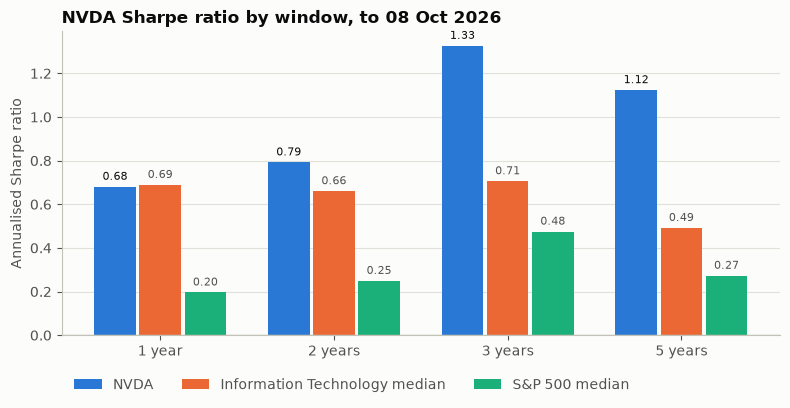

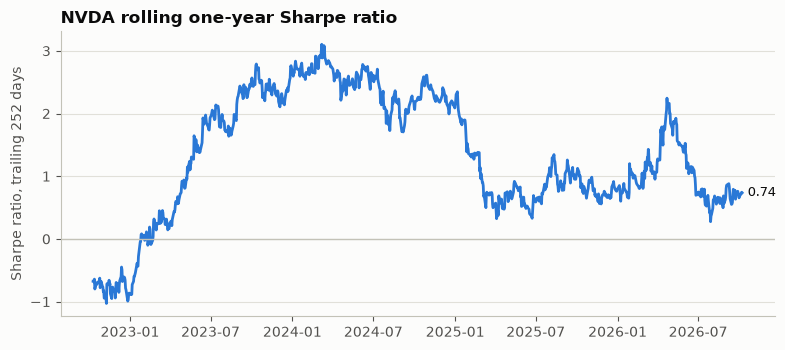

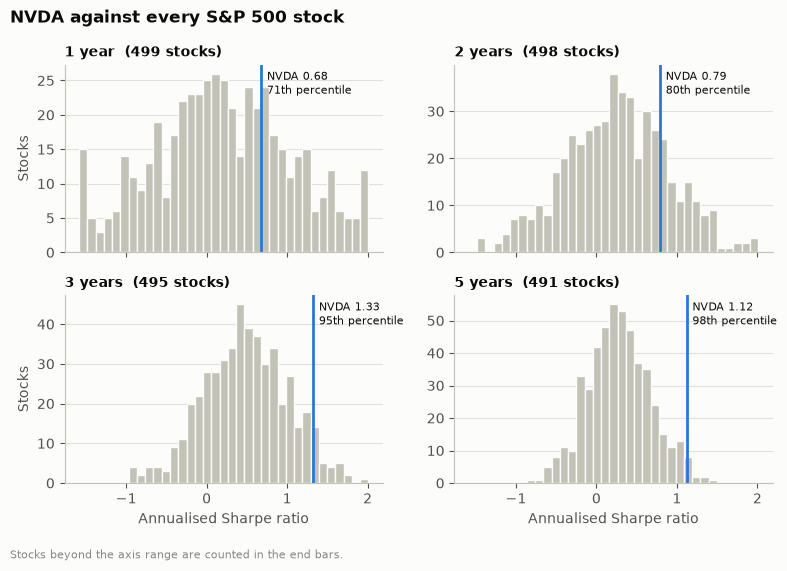

In [ ]:
INK, INK_2, MUTED, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
C_TICKER, C_SECTOR, C_INDEX, C_NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASE, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "legend.labelcolor": INK_2,
})
charts = {}


# 1. Sharpe by window
fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(HORIZONS_YEARS))
series = [(f"{ticker}", mine["sharpe_ratio"], C_TICKER),
          (f"{sector} median", bench["sector_median"], C_SECTOR),
          ("S&P 500 median", bench["index_median"], C_INDEX)]
width = 0.26
for i, (label, vals, color) in enumerate(series):
    vals = vals.reindex(HORIZONS_YEARS)
    bars = ax.bar(x + (i - 1) * width, vals.fillna(0), width * 0.92, label=label, color=color)
    for b, v in zip(bars, vals):
        txt = "n/a" if pd.isna(v) else f"{v:.2f}"
        ax.annotate(txt, (b.get_x() + b.get_width() / 2, max(v, 0) if pd.notna(v) else 0), xytext=(0, 3),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8,
                    color=INK if i == 0 else INK_2)
ax.axhline(0, color=BASE, linewidth=1)
ax.set_xticks(x, [f"{h} year{'s' if h > 1 else ''}" for h in HORIZONS_YEARS])
ax.set_ylabel("Annualised Sharpe ratio")
ax.set_title(f"{ticker} Sharpe ratio by window, to {END_DATE:%d %b %Y}")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.1), ncol=3)
fig.tight_layout()
charts["sharpe_by_window"] = fig


# 2. Rolling one-year Sharpe
r = panel.loc[panel["ticker"] == ticker].set_index("date")["daily_return"]
rf_daily = (1 + RISK_FREE_RATE) ** (1 / TRADING_DAYS) - 1
rolling = ((r - rf_daily).rolling(TRADING_DAYS).mean() / r.rolling(TRADING_DAYS).std()) * np.sqrt(TRADING_DAYS)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(rolling.index, rolling, color=C_TICKER, linewidth=2)
ax.axhline(0, color=BASE, linewidth=1)
if rolling.notna().any():
    last = rolling.dropna().iloc[-1]
    ax.annotate(f"{last:.2f}", (rolling.dropna().index[-1], last), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_ylabel("Sharpe ratio, trailing 252 days")
ax.set_title(f"{ticker} rolling one-year Sharpe ratio")
fig.tight_layout()
charts["rolling_sharpe"] = fig


# 3. Distribution across the index, one panel per window
fig, axes = plt.subplots(2, 2, figsize=(8, 5.6), sharex=True)
lo, hi = sharpe_all["sharpe_ratio"].quantile([0.005, 0.995])
bins = np.linspace(min(lo, mine["sharpe_ratio"].min(skipna=True) if mine["sharpe_ratio"].notna().any() else lo),
                   max(hi, mine["sharpe_ratio"].max(skipna=True) if mine["sharpe_ratio"].notna().any() else hi), 36)
for ax, h in zip(axes.flat, HORIZONS_YEARS):
    vals = sharpe_all.loc[sharpe_all["horizon_years"] == h, "sharpe_ratio"].dropna().clip(bins[0], bins[-1])
    ax.hist(vals, bins=bins, color=C_NEUTRAL, edgecolor=SURFACE, linewidth=1)
    v = mine.at[h, "sharpe_ratio"]
    if pd.notna(v):
        ax.axvline(v, color=C_TICKER, linewidth=2)
        ax.annotate(f"{ticker} {v:.2f}\n{mine.at[h, 'rank_in_index_pct']:.0f}th percentile", (v, 1), xycoords=("data", "axes fraction"),
                    xytext=(4, -4), textcoords="offset points", va="top", fontsize=8, color=INK)
    else:
        ax.text(0.98, 0.95, f"{ticker}: not enough history", transform=ax.transAxes, ha="right", va="top",
                fontsize=8, color=INK_2)
    ax.set_title(f"{h} year{'s' if h > 1 else ''}  ({len(vals)} stocks)", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("Annualised Sharpe ratio")
for ax in axes[:, 0]:
    ax.set_ylabel("Stocks")
fig.suptitle(f"{ticker} against every S&P 500 stock", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.0, "Stocks beyond the axis range are counted in the end bars.", fontsize=8, color=MUTED)
fig.tight_layout(rect=(0, 0.03, 1, 1))
charts["sharpe_distribution"] = fig

for name, f in charts.items():
    f.savefig(out_dir / f"{ticker}_{name}.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Markdown report
Writes `sharpe_report_<TICKER>.md` with the table and the three charts, and shows it here.
With `EMBED_IMAGES_IN_MARKDOWN = True` the charts are inside the file, so it can be shared on its own.

Saved /home/suhana/GitHub/mod2_sp_elt/kenny/sharpe_output/sharpe_report_NVDA.md


# NVDA (Nvidia): Sharpe ratio report

**Sector:** Information Technology · **Data to:** 08 October 2026 · **Risk-free rate:** 4.00% a year

| Window | Sharpe | Information Technology median | S&P 500 median | Annual return | Annual volatility | Total return | Percentile in S&P 500 |
|---|---|---|---|---|---|---|---|
| 1 year | **0.68** | 0.69 | 0.20 | 29.6% | 37.7% | 25.1% | 71 |
| 2 years | **0.79** | 0.66 | 0.25 | 38.7% | 43.8% | 78.1% | 80 |
| 3 years | **1.33** | 0.71 | 0.48 | 66.0% | 46.8% | 417.5% | 95 |
| 5 years | **1.12** | 0.49 | 0.27 | 62.2% | 51.9% | 1038.4% | 98 |

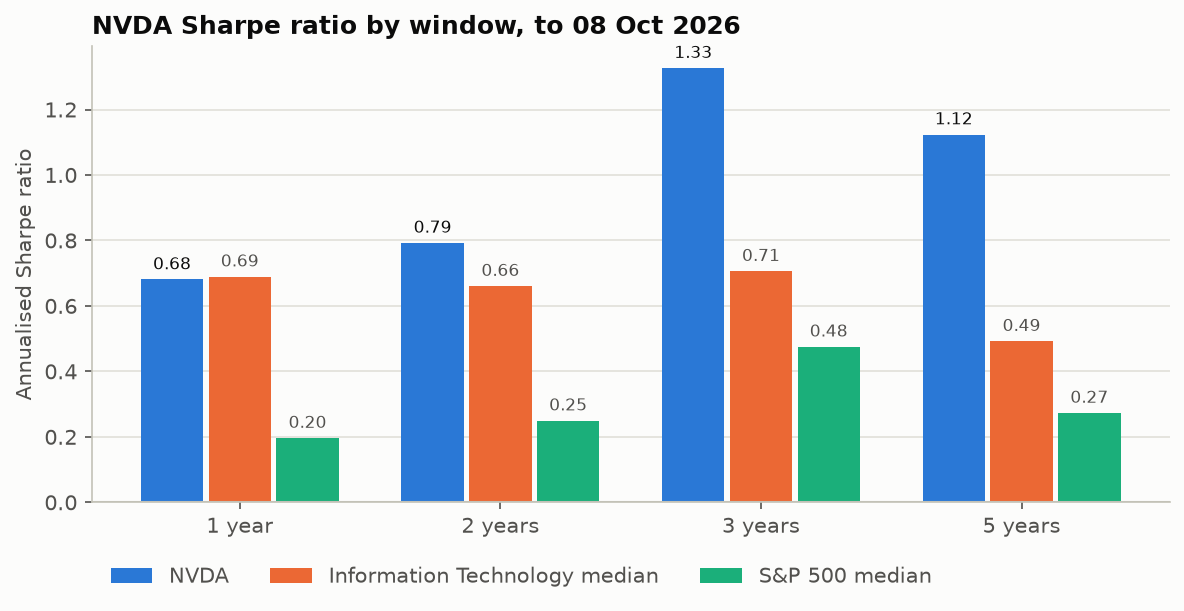

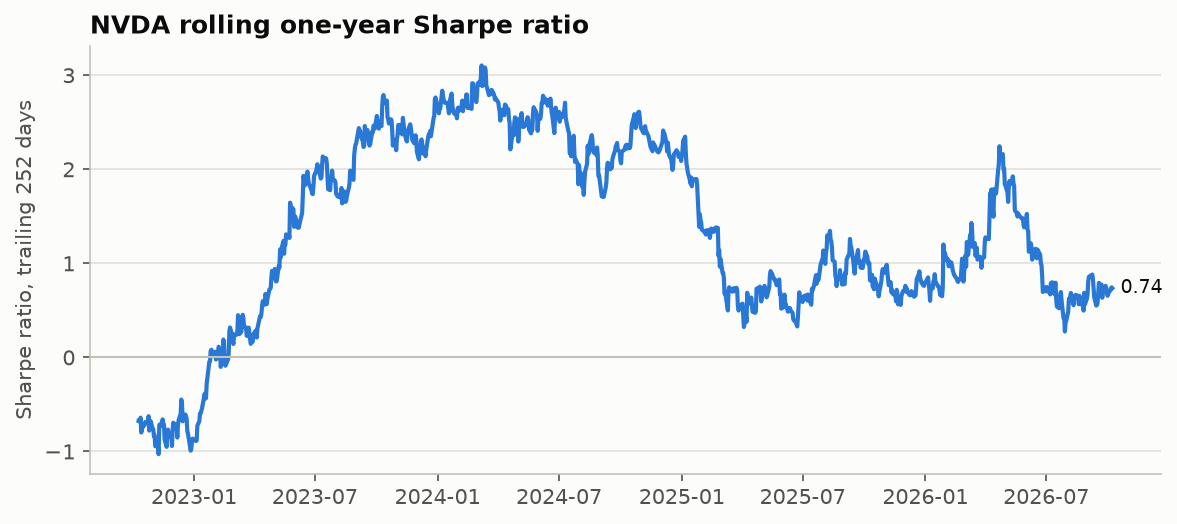

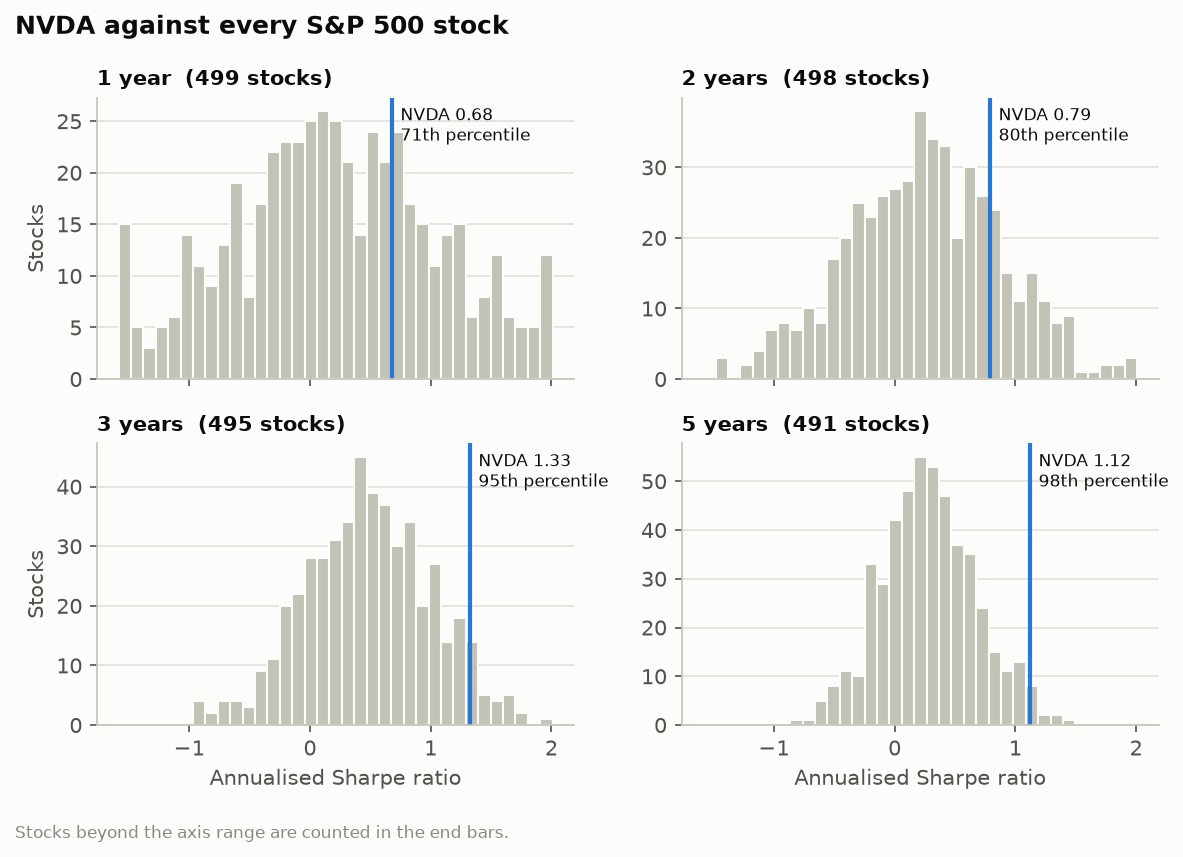

## Method
- Daily return: change in `adj_close` (split- and dividend-adjusted) from the previous trading day.
- Sharpe ratio: mean daily return minus the daily risk-free rate, divided by the standard deviation of daily returns,
  times sqrt(252).
- An N-year window runs from the close N years before 08 October 2026 to that date. Stocks listed for less than
  the full window have no value for it.
- Medians and ranks use today's S&P 500 members only, so they exclude companies that left the index.


In [ ]:
def image_link(name: str) -> str:
    path = out_dir / f"{ticker}_{name}.png"
    if EMBED_IMAGES_IN_MARKDOWN:
        return "data:image/png;base64," + base64.b64encode(path.read_bytes()).decode()
    return path.name


def pct(v):
    return "n/a" if pd.isna(v) else f"{v:.1%}"


def num(v, fmt="{:.2f}"):
    return "n/a" if pd.isna(v) else fmt.format(v)


rows = "\n".join(
    f"| {h} year{'s' if h > 1 else ''} | **{num(mine.at[h, 'sharpe_ratio'])}** | {num(bench.at[h, 'sector_median'])} "
    f"| {num(bench.at[h, 'index_median'])} | {pct(mine.at[h, 'annual_return'])} | {pct(mine.at[h, 'annual_volatility'])} "
    f"| {pct(mine.at[h, 'total_return'])} | {num(mine.at[h, 'rank_in_index_pct'], '{:.0f}')} |"
    for h in HORIZONS_YEARS)

report = f"""# {ticker} ({company}): Sharpe ratio report

**Sector:** {sector} · **Data to:** {END_DATE:%d %B %Y} · **Risk-free rate:** {RISK_FREE_RATE:.2%} a year

| Window | Sharpe | {sector} median | S&P 500 median | Annual return | Annual volatility | Total return | Percentile in S&P 500 |
|---|---|---|---|---|---|---|---|
{rows}

![Sharpe ratio by window]({image_link('sharpe_by_window')})

![Rolling one-year Sharpe ratio]({image_link('rolling_sharpe')})

![{ticker} against every S&P 500 stock]({image_link('sharpe_distribution')})

## Method
- Daily return: change in `adj_close` (split- and dividend-adjusted) from the previous trading day.
- Sharpe ratio: mean daily return minus the daily risk-free rate, divided by the standard deviation of daily returns,
  times sqrt({TRADING_DAYS}).
- An N-year window runs from the close N years before {END_DATE:%d %B %Y} to that date. Stocks listed for less than
  the full window have no value for it.
- Medians and ranks use today's S&P 500 members only, so they exclude companies that left the index.
"""
report_path = out_dir / f"sharpe_report_{ticker}.md"
report_path.write_text(report, encoding="utf-8")
print(f"Saved {report_path.resolve()}")
display(Markdown(report))

## 7. The same calculation in BigQuery
Writes `sharpe_all_tickers_bigquery.sql`: one query that returns the step 3 table for every ticker and window.
Paste it into the BigQuery console, replacing the table name if `BQ_TABLE` is not set.

To run it from here instead, set `BQ_TABLE` in the settings cell and install the client once with
`%pip install google-cloud-bigquery db-dtypes`; the cell then compares BigQuery's answers with step 3.

In [ ]:
horizon_list = ", ".join(str(h) for h in HORIZONS_YEARS)
table = BQ_TABLE or "your_project.your_dataset.sp500_panel"
bq_sql = f"""-- Sharpe ratio for every ticker over the last {horizon_list} years (BigQuery)
-- Daily Sharpe = mean(daily return - daily risk-free rate) / stdev(daily return); annualised x SQRT({TRADING_DAYS}).
-- Works whether `date` was loaded as DATE or as text.
WITH params AS (
  SELECT POW(1 + {RISK_FREE_RATE}, 1 / {TRADING_DAYS}) - 1 AS rf_daily
),
prices AS (
  SELECT ticker, SAFE_CAST(`date` AS DATE) AS d, adj_close
  FROM `{table}`
  WHERE adj_close IS NOT NULL
),
returns AS (
  SELECT ticker, d, adj_close / LAG(adj_close) OVER (PARTITION BY ticker ORDER BY d) - 1 AS r
  FROM prices
),
first_day AS (
  SELECT ticker, MIN(d) AS first_d FROM prices GROUP BY ticker
),
windows AS (
  SELECT h AS horizon_years, DATE_SUB(MAX(d), INTERVAL h YEAR) AS start_date, MAX(d) AS end_date
  FROM prices, UNNEST([{horizon_list}]) AS h
  GROUP BY h
)
SELECT
  r.ticker,
  w.horizon_years,
  w.start_date,
  w.end_date,
  COUNT(r.r)                                              AS trading_days,
  AVG(r.r)                                                AS daily_mean_return,
  STDDEV_SAMP(r.r)                                        AS daily_volatility,
  SAFE_DIVIDE(AVG(r.r) - ANY_VALUE(p.rf_daily), STDDEV_SAMP(r.r))                   AS sharpe_daily,
  SAFE_DIVIDE(AVG(r.r) - ANY_VALUE(p.rf_daily), STDDEV_SAMP(r.r)) * SQRT({TRADING_DAYS}) AS sharpe_ratio,
  AVG(r.r) * {TRADING_DAYS}                               AS annual_return,
  STDDEV_SAMP(r.r) * SQRT({TRADING_DAYS})                 AS annual_volatility,
  EXP(SUM(LN(1 + r.r))) - 1                               AS total_return
FROM returns AS r
JOIN first_day AS f USING (ticker)
CROSS JOIN windows AS w
CROSS JOIN params AS p
WHERE r.r IS NOT NULL
  AND r.d > w.start_date
  AND r.d <= w.end_date
  AND f.first_d <= w.start_date            -- only stocks listed for the whole window
GROUP BY r.ticker, w.horizon_years, w.start_date, w.end_date
ORDER BY w.horizon_years, sharpe_ratio DESC
"""
sql_path = out_dir / "sharpe_all_tickers_bigquery.sql"
sql_path.write_text(bq_sql, encoding="utf-8")
print(f"Saved {sql_path.resolve()}")

if BQ_TABLE:
    try:
        from google.cloud import bigquery
    except ImportError:
        raise SharpeError("The BigQuery client is not installed. Run: %pip install google-cloud-bigquery db-dtypes") from None
    try:
        bq = bigquery.Client().query(bq_sql).to_dataframe()
    except Exception as e:
        raise SharpeError(f"BigQuery could not run the query: {str(e).splitlines()[0]}") from None
    both = sharpe_all.dropna(subset=["sharpe_ratio"]).merge(bq, on=["ticker", "horizon_years"], suffixes=("", "_bq"))
    gap = (both["sharpe_ratio"] - both["sharpe_ratio_bq"]).abs().max()
    print(f"BigQuery returned {len(bq):,} rows; {len(both):,} match step 3; largest Sharpe difference {gap:.2e}")
else:
    print("BQ_TABLE is not set, so the query was only written to the file above.")

Saved /home/suhana/GitHub/mod2_sp_elt/kenny/sharpe_output/sharpe_all_tickers_bigquery.sql
BQ_TABLE is not set, so the query was only written to the file above.
